In [1]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import numpy as np
import matplotlib.pyplot as plt

print("TensorFlow version:", tf.__version__)
print("Libraries imported successfully!")

TensorFlow version: 2.21.0
Libraries imported successfully!


In [2]:
(x_train, y_train), (x_test, y_test) = keras.datasets.cifar10.load_data()

# Convert labels from shape (n, 1) to (n,)
y_train = y_train.flatten()
y_test = y_test.flatten()

print("Training images:", x_train.shape)
print("Training labels:", y_train.shape)
print("Testing images:", x_test.shape)
print("Testing labels:", y_test.shape)

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 1225s 7us/step
Training images: (50000, 32, 32, 3)
Training labels: (50000,)
Testing images: (10000, 32, 32, 3)
Testing labels: (10000,)


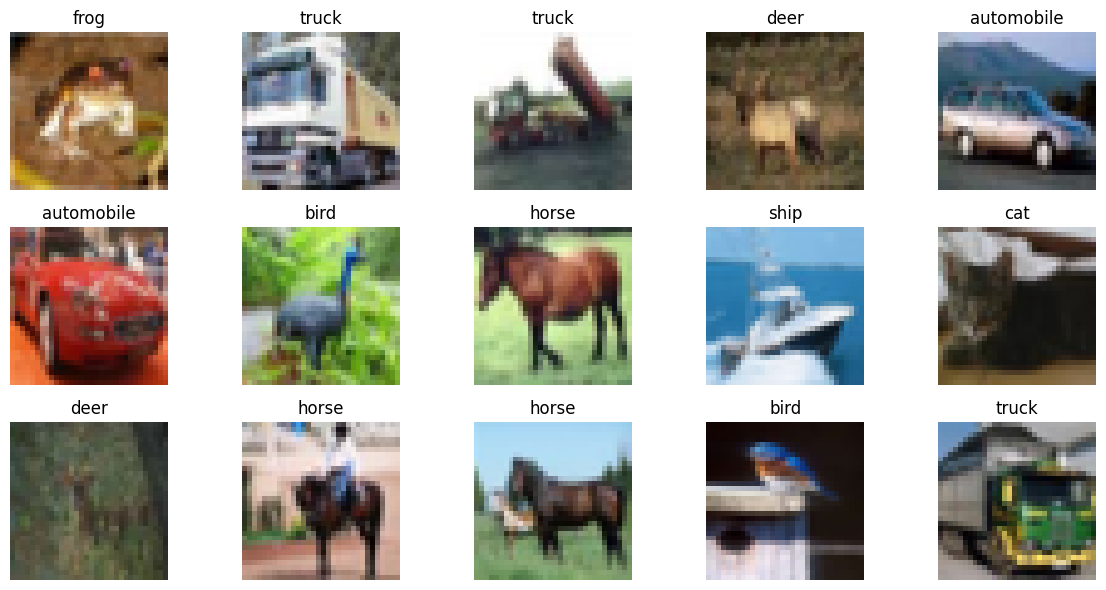

In [3]:
class_names = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]

plt.figure(figsize=(12, 6))

for i in range(15):
    plt.subplot(3, 5, i + 1)
    plt.imshow(x_train[i])
    plt.title(class_names[y_train[i]])
    plt.axis("off")

plt.tight_layout()
plt.show()

In [4]:
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

print("Minimum pixel value:", x_train.min())
print("Maximum pixel value:", x_train.max())
print("Training data shape:", x_train.shape)

Minimum pixel value: 0.0
Maximum pixel value: 1.0
Training data shape: (50000, 32, 32, 3)


In [5]:
model = keras.Sequential([
    keras.Input(shape=(32, 32, 3)),

    layers.Conv2D(32, (3, 3), padding="same", activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), padding="same", activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), padding="same", activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),

    layers.Dense(128, activation="relu"),
    layers.Dropout(0.4),

    layers.Dense(10, activation="softmax")
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 356,810 (1.36 MB)

 Trainable params: 356,810 (1.36 MB)

 Non-trainable params: 0 (0.00 B)

In [6]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model compiled successfully!")

Model compiled successfully!


In [7]:
callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    ),

    keras.callbacks.ModelCheckpoint(
        "cifar10_cnn_best.keras",
        monitor="val_loss",
        save_best_only=True
    )
]

history = model.fit(
    x_train,
    y_train,
    epochs=20,
    batch_size=128,
    validation_split=0.2,
    callbacks=callbacks,
    verbose=1
)

Epoch 1/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 84s 262ms/step - accuracy: 0.3726 - loss: 1.7053 - val_accuracy: 0.4985 - val_loss: 1.3850
Epoch 2/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 141s 259ms/step - accuracy: 0.5195 - loss: 1.3386 - val_accuracy: 0.5659 - val_loss: 1.2232
Epoch 3/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 82s 259ms/step - accuracy: 0.5882 - loss: 1.1660 - val_accuracy: 0.6370 - val_loss: 1.0274
Epoch 4/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 82s 261ms/step - accuracy: 0.6298 - loss: 1.0468 - val_accuracy: 0.6649 - val_loss: 0.9423
Epoch 5/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 86s 274ms/step - accuracy: 0.6610 - loss: 0.9633 - val_accuracy: 0.6838 - val_loss: 0.9059
Epoch 6/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 81s 260ms/step - accuracy: 0.6869 - loss: 0.8882 - val_accuracy: 0.7080 - val_loss: 0.8447
Epoch 7/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 81s 260ms/step - accuracy: 0.7127 - loss: 0.8203 - val_accuracy: 0.7148 - val_loss: 0.8162
Epoch 8/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 82s 261ms/step - accuracy: 0.7273 - loss: 

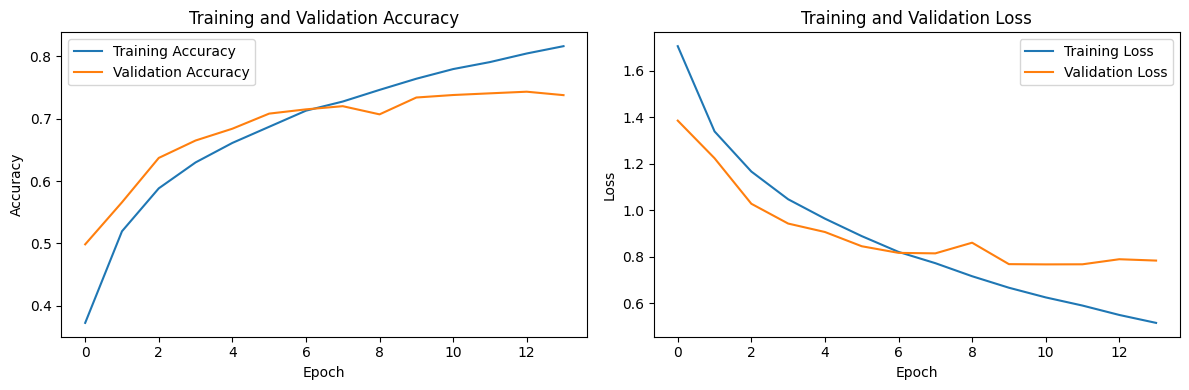

In [8]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [9]:
test_loss, test_accuracy = model.evaluate(
    x_test,
    y_test,
    verbose=0
)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

Test Loss: 0.7874
Test Accuracy: 73.54%


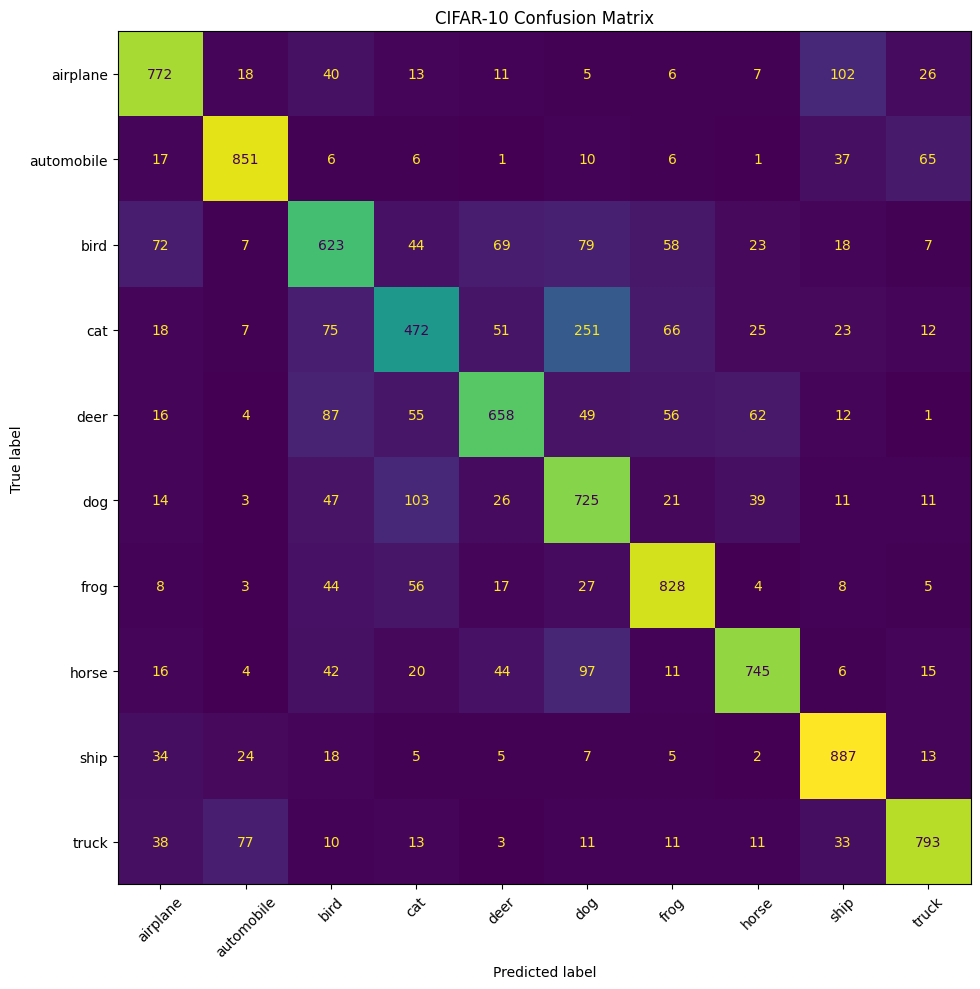

              precision    recall  f1-score   support

    airplane       0.77      0.77      0.77      1000
  automobile       0.85      0.85      0.85      1000
        bird       0.63      0.62      0.63      1000
         cat       0.60      0.47      0.53      1000
        deer       0.74      0.66      0.70      1000
         dog       0.57      0.72      0.64      1000
        frog       0.78      0.83      0.80      1000
       horse       0.81      0.74      0.78      1000
        ship       0.78      0.89      0.83      1000
       truck       0.84      0.79      0.81      1000

    accuracy                           0.74     10000
   macro avg       0.74      0.74      0.73     10000
weighted avg       0.74      0.74      0.73     10000



In [10]:
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)

probabilities = model.predict(x_test, verbose=0)
y_pred = np.argmax(probabilities, axis=1)

cm = confusion_matrix(y_test, y_pred)

fig, ax = plt.subplots(figsize=(10, 10))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(ax=ax, xticks_rotation=45, colorbar=False)
plt.title("CIFAR-10 Confusion Matrix")
plt.tight_layout()
plt.show()

print(classification_report(
    y_test,
    y_pred,
    labels=list(range(10)),
    target_names=class_names,
    zero_division=0
))

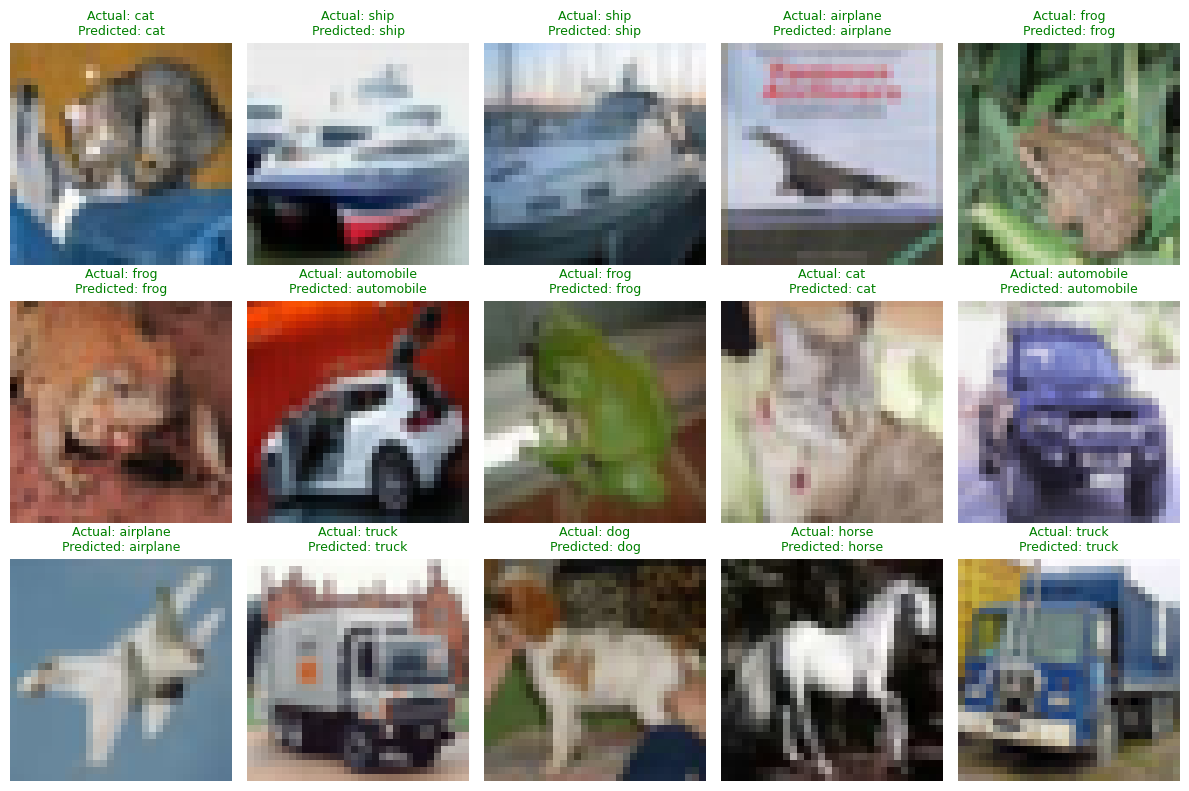

In [11]:
plt.figure(figsize=(12, 8))

for i in range(15):
    predicted_class = int(y_pred[i])
    actual_class = int(y_test[i])

    plt.subplot(3, 5, i + 1)
    plt.imshow(x_test[i])

    colour = "green" if predicted_class == actual_class else "red"

    plt.title(
        f"Actual: {class_names[actual_class]}\n"
        f"Predicted: {class_names[predicted_class]}",
        color=colour,
        fontsize=9
    )
    plt.axis("off")

plt.tight_layout()
plt.show()

In [12]:
model.save("cifar10_cnn_final.keras")

print("Model saved successfully!")

Model saved successfully!
